In [50]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import nivapy3 as nivapy
import numpy as np

from pathlib import Path
from tqdm.notebook import tqdm

In [2]:
# Connect to the 'general' database as a 'read-only' user
eng = nivapy.da.connect_postgis()

Connection successful.


# Collate catchment data into a single master table

QC here has raised the following areas for future improvement in the overall workflow:

- Lots of data being included from small streams monitoring quarries. Future improvement: get quarry shapefile, identify monitoring points near quarries with catchment area below a certain size, and exclude them. Shorter-term, try dropping tiltaksorientert overvåking points from ML. Data loss vs improvement in performance? Probably also tonnes of other contaminated sites; ways of identifying them? Landfill registry?
- Catchment delineation allows outflows to be moved out into the sea. Need to not allow that somehow. Check whether delineated catchments cross into the sea (substantially).

User choices:
1. TOC or DOC? If TOC: for catchments with less than 20% agriculture, predict TOC as DOC * 1.03. Drop sites with >= 20% agriculture (can no longer predict TOC from DOC because of particles).
2. Drop crossborder catchments?
3. Drop Vestfold lab data within sites, flagged as likely dodgy?
4. Only include sites with n_samples >= min_samps. E.g. here, choose 10. We have much more confidence that these have correct catchment boundaries, as I manually checked them (see previous notebooks).

**Future to do:**
* Add water chem metadata to static_df and output that too, with all sites (not limited by n_samps). i.e. add columns n_samps, start_year, end_year, perhaps also main activity name (mode of activities?). Then it's easier in the future to filter the sites you want to build the daily data matrix based on.
* Explore dropping different kinds of activities which are likely to include contaminated sites, where the sources of contamination aren't captured in the features. (Though at the risk of loosing "good" sites too).

In [36]:
# ----------- SETUP --------------

# Variable to predict
y_var = 'TOC_mg_l'  # one of 'TOC_mg_l' or 'DOC_mg_l'
yvar_short = "toc"

# Only keep sites with >= min_samps
min_samps = 10

# Chem data cleaning to apply
drop_vestfold_within_site_data = True  # True to help with temporal consistency
drop_vestfold_full_site_data = False  # False to preserve spatial representativeness

# Drop catchments which have substantial portion outside Norway?
drop_crossborder = True

# First and last dates
st_dt = '1980-01-01'
end_dt = '2025-12-31'

# -------- Column names ---------
id_col = 'site_code'  # set as index for static dfs

# ---------- Directories/filepaths ----------
data_dir = r"/home/jovyan/shared/common/norsink/vm_catchments_data"
catchment_set = "monitored-oc-catchs"

# Static catchment properties

## Basic catchment metadata

In [4]:
pt_dir = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments"
pts_fpath = os.path.join(pt_dir, "outlet_locations_vm-rivs-quant-oc_v3-full.csv")
pts_df = pd.read_csv(pts_fpath, index_col=0)

# (N.B. only column 'frac_outside_no' to be used for filtering, the others are useful but contain NaNs)
pts_df = pts_df.rename(
    {
        "frac_sw": "fraction_sweden",
        "frac_ru": "fraction_russia",
        "frac_fi": "fraction_finland",
    },
    axis=1,
)

# Split columns into those that will be metadata, and those that will go into master table
# Keep track of metadata cols, for collating at end
metadata_cols = [
    'site_id',
    'Name',
    'start_year',
    'end_year',
    'n_years',
    'n_samples',
    'vassomnr',
    'pt_in_lake',  # Could be feature AND metadata
    'fraction_sweden',  # contain NaNs
    'fraction_finland',  # contain NaNs
    'fraction_russia',  # contain NaNs    
    'frac_outside_no',
]

site_compile_cols = [
    'lon',
    'lat',
    'area_km2'
]
print("cols to add to master table:", site_compile_cols)

# ------- QC - lakes, crossborder catchs ---------

print("Number of sites to start with:", len(pts_df))

# How many points will we be removing with the given min_samps?
low_n_samp_sites = pts_df[pts_df['n_samples'] < min_samps].index
print("Number of sites that will be dropped due to low n_samps:", len(low_n_samp_sites))
print("Remaining sites:", len(pts_df) - len(low_n_samp_sites))

# Useful metadata (or potentially features)
print("Number of points in lakes:", (pts_df['pt_in_lake'] == True).sum())

# Probably drop sites where > 50% of the delimited catchment is outside Norway?
# Though maybe do this based on vassdragsområdenummer as well/instead?
crossborder_catchs = pts_df.loc[pts_df['frac_outside_no'] > 0.5]
print("Number of crossborder catchs (>50% outside NO):", len(crossborder_catchs))
display(crossborder_catchs)

# List of catchchment ids to add to "drop" list
if drop_crossborder:
    crossborder_catchs_li = list(crossborder_catchs.index)
else:
    crossborder_catchs_li = None

cols to add to master table: ['lon', 'lat', 'area_km2']
Number of sites to start with: 8482
Number of sites that will be dropped due to low n_samps: 5924
Remaining sites: 2558
Number of points in lakes: 173
Number of crossborder catchs (>50% outside NO): 17


,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,pt_in_lake,area_km2,fraction_sweden,fraction_finland,fraction_russia,frac_outside_no
site_code,,,,,,,,,,,,,,,
001-30735,11.537422,58.877626,30735,ENI4 ENNINGDALSELVA,1991,1991,1.0,5,5.00,False,124.153424,0.968068,0.000000,0.00000,0.968068
001-30745,11.490473,58.960694,30745,Enningdalselva (ENI 2),1991,2010,18.7,30,1.60,False,212.224869,0.580317,0.000000,0.00000,0.580317
001-31059,11.520638,58.910288,31059,ENI3 ENNINGDALSELVA,1991,1991,1.0,5,5.00,False,191.358069,0.643600,0.000000,0.00000,0.643600
001-61955,11.687507,59.479914,61955,Braneselva,2012,2012,1.0,2,2.00,False,10.159504,0.556863,0.000000,0.00000,0.556863
001-62044,11.711326,59.485813,62044,Braneselva v/Foss,2012,2012,1.0,2,2.00,False,6.444111,0.862605,0.000000,0.00000,0.862605
001-62045,11.684948,59.477881,62045,"Braneselva nedstrøms E18, 16_08",2012,2012,1.0,2,2.00,False,10.317495,0.548336,0.000000,0.00000,0.548336
124-104986,12.036398,63.335585,104986,Steinfjellgrenda,2021,2022,1.0,2,2.00,False,16.228020,0.856263,0.000000,0.00000,0.856263
124-104987,12.031988,63.340020,104987,Mellomveien,2021,2021,1.0,1,1.00,False,18.977961,0.828958,0.000000,0.00000,0.828958
234-63085,28.050541,70.050751,63085,Polmakelva (Buolbmátjohka) ovenfor avfallsfylling,2013,2013,1.0,3,3.00,False,772.488600,0.000000,0.804516,0.00000,0.804516


In [5]:
pts_df.describe()

,lon,lat,site_id,start_year,end_year,n_years,n_samples,av_freq,area_km2,fraction_sweden,fraction_finland,fraction_russia,frac_outside_no
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8375.000000,8375.000000,8375.000000,8482.000000
mean,9.913985,61.265743,79832.116954,2015.319854,2019.151026,4.359785,19.646899,3.851870,371.046094,0.002543,0.000668,0.000402,0.003567
std,3.602953,2.740834,29453.977219,8.567172,7.128063,6.207766,81.779150,7.389164,2071.385570,0.034275,0.017614,0.012576,0.040312
min,4.693305,58.018357,-11.000000,1980.000000,1983.000000,1.000000,1.000000,0.060000,0.314898,0.000000,0.000000,0.000000,0.000000
25%,7.706517,59.579832,56484.250000,2013.000000,2017.000000,1.000000,2.000000,1.000000,2.223637,0.000000,0.000000,0.000000,0.000000
50%,9.952011,60.361049,84850.000000,2017.000000,2021.000000,1.000000,4.500000,2.170000,8.748207,0.000000,0.000000,0.000000,0.000000
75%,10.999183,61.942946,103955.750000,2021.000000,2024.000000,5.700000,12.000000,4.530000,51.573524,0.000000,0.000000,0.000000,0.000000
max,30.952229,70.962425,127364.000000,2025.000000,2026.000000,44.900000,2020.000000,246.040000,41698.280949,1.000000,1.000000,0.572790,1.000000


In [6]:
# plot_cols = ['n_years', 'n_samples', 'area_km2']

# titles = {
#     'n_years': 'Record length (years)',
#     'n_samples': 'Samples per site',
#     'av_freq': 'Sampling frequency (yr$^{-1}$)',
#     'area_km2': 'Catchment area (km$^2$)'
# }

# fig, axes = plt.subplots(1, len(plot_cols), figsize=(8, 4))

# for ax, col in zip(axes, plot_cols):

#     ax.boxplot(
#         pts_df[col].dropna(),
#         whis=(5, 95),
#         patch_artist=True,
#         boxprops=dict(facecolor='lightsteelblue'),
#         medianprops=dict(color='black', linewidth=2),
#         flierprops=dict(
#             marker='o',
#             markersize=4,
#             markerfacecolor='tab:blue',
#             markeredgecolor='tab:blue',
#             alpha=0.6
#         )
#     )

#     ax.set_title(titles[col], fontsize=11)
#     ax.set_xticks([])
#     ax.grid(axis='y', alpha=0.3)

# # Log scale for area
# axes[1].set_yscale('log')
# axes[2].set_yscale('log')
# # axes[3].set_yscale('log')

# plt.tight_layout()
# plt.show()

In [7]:
# vassom (& eventually regine) info
fpath = os.path.join(data_dir, f"{catchment_set}_static_vassom-reginer.csv")

riv_network_df = pd.read_csv(fpath, index_col=0)
riv_network_df.head()

,vassomnr
site_code,
001-119928,1
001-119929,1
001-30653,1
001-30683,1
001-30687,1


## Derived static properties

Slope, elevation, land cover, ndvi, WWTW+industry inputs

In [8]:
# Output folder (csv added here)
catchment_set = "monitored-oc-catchs"  # for filenaming
out_folder = r"/home/jovyan/shared/common/norsink/vm_catchments_data"

# From NB 01_static_catchment_properties
slope_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_slope.csv")
slope_noagri_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_slope-nonagri.csv")
elev_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_elevation.csv")
ndvi_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_ndvi.csv")

# From NB 01b_ar50_raster_stats
lu_fpath = os.path.join(out_folder, f"{catchment_set}_stats_static_lu_raster.csv")

# From NB 02_annual_inputs (though it's actually static)
t3_fpath = os.path.join(out_folder, f"{catchment_set}_static_teotil3_point-inputs_2017-2024.csv")

### Slope (whole catch and non-agricultural land only)

#### Whole catchment

In [9]:
slope_df = pd.read_csv(slope_fpath, index_col=0)

if len(slope_df.loc[slope_df['slope_deg_valid_frac'] < 1]) == 0:
    slope_df = slope_df.drop(['slope_deg_valid_frac'], axis=1)

drop_cols = ['Name', 'slope_deg_lt2_count', 'slope_deg_lt5_count', 'slope_deg_min', 'slope_deg_max', 'total_count']
slope_df = slope_df.drop(drop_cols, axis=1)

slope_df.describe()

,slope_deg_mean,slope_deg_std,slope_deg_median,slope_deg_percentile_5,slope_deg_percentile_95,slope_deg_lt2_frac,slope_deg_lt5_frac
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000
mean,10.054703,6.798111,8.800763,1.429277,23.041370,0.135432,0.347205
std,5.115042,3.058115,5.050235,1.339821,10.426759,0.127287,0.210890
min,0.263755,0.137976,0.240793,0.000000,0.527520,0.000000,0.000000
25%,6.576344,4.598492,5.510260,0.573365,15.573688,0.055556,0.190036
50%,9.022896,6.313412,7.713648,1.110272,21.269325,0.099658,0.307992
75%,12.401927,8.547180,10.840158,1.859293,29.132576,0.165069,0.453714
max,40.815123,21.270218,43.679131,23.307161,69.798668,1.000000,1.000000


#### On non-agricultural land only

What to do when the whole catchment is agricultural, so this is (rightly) NaN?

See this is not often the case (only 1 catchment with 3 d.p.), so just drop that row.

In [10]:
# Slope on non-agricultural land
slope_nonagri_df = pd.read_csv(slope_noagri_fpath, index_col=0)

drop_cols = ['Name', 'slope_nonagri_deg_lt2_count', 'slope_nonagri_deg_lt5_count', 'slope_nonagri_deg_min', 'slope_nonagri_deg_max', 'total_count', 'slope_nonagri_deg_valid_frac']

slope_nonagri_df = slope_nonagri_df.drop(drop_cols, axis=1)

slope_nonagri_df.describe()

,slope_nonagri_deg_mean,slope_nonagri_deg_std,slope_nonagri_deg_median,slope_nonagri_deg_percentile_5,slope_nonagri_deg_percentile_95,slope_nonagri_deg_lt2_frac,slope_nonagri_deg_lt5_frac
count,8481.000000,8481.000000,8481.000000,8481.000000,8481.000000,8482.000000,8482.000000
mean,10.481572,6.867620,9.283710,1.604133,23.523579,0.213817,0.387804
std,5.274599,2.997387,5.236048,1.607664,10.388778,0.190068,0.221559
min,0.287591,0.183603,0.232186,0.000000,0.675702,0.000000,0.000000
25%,6.978338,4.719215,5.893564,0.625935,16.098200,0.087971,0.222716
50%,9.364429,6.397779,8.113046,1.226092,21.731764,0.149371,0.341019
75%,12.850347,8.567671,11.381905,2.049226,29.532084,0.269143,0.509205
max,42.910849,19.549633,45.001820,23.307161,70.002365,1.000000,1.000000


In [11]:
# How many NaNs (i.e.100% agriculture, so whole catchment is masked)?
rows_with_na = slope_nonagri_df.loc[slope_nonagri_df['slope_nonagri_deg_mean'].isna()]

# Look at the one catchment with a NaN - see it's small and 100% agriculture (cross-check with vannmiljø)
# And only has 3 d.p. So just drop it
# display(cat_df.loc['128-29619', :])
# slope_df.loc['128-29619', :]

print("Rows before dropping NaNs:", len(slope_nonagri_df))
slope_nonagri_df = slope_nonagri_df.dropna()
print("Rows after dropping NaNs:", len(slope_nonagri_df))

Rows before dropping NaNs: 8482
Rows after dropping NaNs: 8481


### Elevation

To do: what's going on with catchments with substantial portion of area < sea level? Cross-check against n_samps and LU cover.

Find:
- If catchments have 5th percentile below sea level, that's a substantial portion of the catchment. If not much water chem data -> drop. If lots of data -> manually check what's going on, e.g. in Vannmiljø. For TOC, find it's a (deep) quarry, i.e. want to drop anyway. So remove all sites with 5th percentile below sea level.

- For catchments that have some cells below sea level:
    - If catchment area is large, don't worry about it, assume just small coastal issues.
    - If area is small: if not many data points, drop. If lots of data points, manually check and decide whether to delete or keep/adjust catchment boundary. Find there aren't any with lots of d.p.

In [12]:
elev_df = pd.read_csv(elev_fpath, index_col=0)

if len(elev_df.loc[elev_df['elev_m_valid_frac'] < 1]) == 0:
    elev_df = elev_df.drop(['elev_m_valid_frac'], axis=1)

drop_cols = ['Name', 'total_count']
elev_df = elev_df.drop(drop_cols, axis=1)

elev_cols_to_compile = ['elev_m_mean', 'elev_m_std', 'elev_m_percentile_5', 'elev_m_percentile_95']

elev_df.describe()

,elev_m_mean,elev_m_std,elev_m_median,elev_m_percentile_5,elev_m_percentile_95,elev_m_min,elev_m_max
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000
mean,420.625914,113.114449,421.394819,237.727411,601.347950,166.600934,707.924842
std,329.522083,93.531832,339.031340,251.177470,429.436112,225.079482,518.544404
min,5.506085,0.854037,3.000966,-3.654467,9.475938,-10.070532,10.850326
25%,160.911120,40.541128,154.027733,60.997398,247.100037,17.114725,287.521698
50%,310.399308,84.411700,304.794586,146.201279,481.122604,78.800186,556.639008
75%,624.897798,159.003736,627.376022,313.438080,908.658798,198.254585,1028.117401
max,1767.029715,566.954870,1765.496460,1436.994873,2122.247070,1352.343872,2456.297607


In [13]:
# QC: sites below sea level

sites_below_sl = elev_df.loc[elev_df['elev_m_min'] < 0].index
print("Sites with cells below sea level:", len(sites_below_sl))
cats_below_sl = pts_df.loc[pts_df.index.isin(sites_below_sl), :]

# How many catchments with dodgy elevation data and enough samples that we might care? None.
catchs_below_sl_with_good_data = cats_below_sl.loc[(cats_below_sl['n_samples'] > 7) & (cats_below_sl['area_km2'] < 5)]
if len(catchs_below_sl_with_good_data) == 0:
    print("No small catchments with elevation below sea level with much data. Drop them all.")
else:
    display(catchs_below_sl_with_good_data)

dodgy_elev_cats_to_drop = cats_below_sl.loc[(cats_below_sl['n_samples'] <= 7) & (cats_below_sl['area_km2'] <= 5)]

cats_below_sealevel_li = list(dodgy_elev_cats_to_drop.index)

dodgy_elev_cats_to_drop

Sites with cells below sea level: 32
No small catchments with elevation below sea level with much data. Drop them all.


,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,pt_in_lake,area_km2,fraction_sweden,fraction_finland,fraction_russia,frac_outside_no
site_code,,,,,,,,,,,,,,,
015-51131,10.171287,59.059979,51131,Klåstad,2007,2016,8.9,7,0.79,False,0.458305,0.0,0.0,0.0,0.0
015-60552,10.168683,59.058593,60552,Brattås 1,2016,2016,1.0,3,3.00,False,0.902626,0.0,0.0,0.0,0.0
016-84155,9.854684,59.030068,84155,Askedalsbekken,2016,2016,1.0,4,4.00,False,0.815310,0.0,0.0,0.0,0.0
084-85356,5.102997,61.361485,85356,Askvoll Fristad nord,2017,2022,5.0,5,1.00,False,2.298117,0.0,0.0,0.0,0.0


Klåstad, Brattås 1 and Askedalsbekken are all by big quarries. Delete anyway because of that. Askvoll Fristad north - the delineation has gone wrong, outlet point has been moved out into the sea (Kylleren), probably the real catchment is below the minimum size threshold. Delete. i.e. **safe to drop all these cathchments**.

### NDVI

In [14]:
ndvi_df = pd.read_csv(ndvi_fpath, index_col=0)

ndvi_cols_to_compile = [
    "s2-ndvi-summer_mean",
    "s2-ndvi-summer_std",
    "s2-ndvi-summer_percentile_5",
    "s2-ndvi-summer_percentile_95",
]

ndvi_df

,Name,s2-ndvi-summer_mean,s2-ndvi-summer_std,s2-ndvi-summer_percentile_5,s2-ndvi-summer_percentile_95,s2-ndvi-summer_min,s2-ndvi-summer_max
site_code,,,,,,,
001-119928,Oppstrøms Bommen RA,0.743196,0.080988,0.594708,0.837795,-0.008643,0.912420
001-119929,Nedstrøms Bommen RA,0.743165,0.081065,0.594546,0.837811,-0.008643,0.912420
001-30653,YSTE YSTEHEDEBEKKEN,0.733258,0.094689,0.551792,0.861122,0.176465,0.904451
001-30683,"Unnebergbekken, UNNE",0.703168,0.158880,0.375883,0.858005,-0.043615,0.918342
001-30687,ØRB2 ØRBEKKEN,0.752074,0.073738,0.611978,0.835549,0.111593,0.911715
...,...,...,...,...,...,...,...
313-99151,Hesbølsjøen utløp,0.753945,0.089432,0.591008,0.848733,-0.017626,0.911954
314-46646,"Åkevannet, utløp",0.718406,0.076820,0.567289,0.803218,0.294875,0.861089
314-48074,"Røvatnet, utløp",0.729475,0.098849,0.581484,0.820351,-0.266667,0.886076


In [15]:
ndvi_df.describe()

,s2-ndvi-summer_mean,s2-ndvi-summer_std,s2-ndvi-summer_percentile_5,s2-ndvi-summer_percentile_95,s2-ndvi-summer_min,s2-ndvi-summer_max
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000
mean,0.711635,0.121249,0.479922,0.850830,0.053402,0.905942
std,0.099523,0.061023,0.197697,0.034700,0.223230,0.023584
min,0.095443,0.026822,-0.058324,0.406546,-1.000000,0.703157
25%,0.684399,0.077594,0.383699,0.836607,-0.022985,0.896852
50%,0.743005,0.101032,0.556921,0.855896,0.058696,0.910554
75%,0.773254,0.149236,0.622003,0.873367,0.184558,0.920302
max,0.867275,0.361559,0.804072,0.922360,0.689711,1.000000


### AR50 land cover

Have data for all but 1 site compared to other spatial datasets. Assume this is the one catchmenth 100% outside of Norway (haven't checked).

QC carried out, and used to remove sites:
- If % sea > 5%, remove site (assume delineation has gone wrong)
- Checked how much is "uncategorised": not much, so no need to worry.

In [16]:
lu_df = pd.read_csv(lu_fpath, index_col=0)

rename_cols = {
    'bebygd_pct': 'ar50_urban',
    'jordbruk_pct': 'ar50_agri',
    'skog_pct': 'ar50_forest',
    'snaumark_pct': 'ar50_heath-rock',
    'myr_pct': 'ar50_mire',
    'bre_pct': 'ar50_glacier',
    'ferskvann_pct': 'ar50_freshwater',
    'hav_pct': 'ar50_sea',
    'ikke-kartlagt_pct': 'ar50_uncategorised'
}

lu_df = lu_df.rename(columns=rename_cols)

# Set up cols to be compiled into master
lu_cols = list(rename_cols.values())
drop_cols = ['ar50_sea', 'ar50_uncategorised']
lu_cols_to_compile = [x for x in lu_cols if x not in drop_cols]
print(lu_cols_to_compile)

lu_df.head()

['ar50_urban', 'ar50_agri', 'ar50_forest', 'ar50_heath-rock', 'ar50_mire', 'ar50_glacier', 'ar50_freshwater']


,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,ar50_urban,ar50_agri,ar50_forest,ar50_heath-rock,ar50_mire,ar50_glacier,ar50_freshwater,ar50_sea,ar50_uncategorised
site_code,,,,,,,,,,,,,,,,,,,
002-60284,11.09243,59.270770,60284,"Glomma, Borregård B3",2011,2012,1.0,4,4.00,41698.280949,0.688683,7.395454,49.831983,28.641486,7.989244,0.713362,4.738885,0.000834,0.00007
002-60283,11.10059,59.268050,60283,"Glomma, Borregård B2",2011,2012,1.0,4,4.00,41696.775962,0.687160,7.394695,49.833388,28.642187,7.989534,0.713388,4.739058,0.000520,0.00007
002-60282,11.10680,59.263750,60282,"Glomma, Borregård B1",2011,2012,1.0,4,4.00,41696.357733,0.686873,7.394573,49.833718,28.642359,7.989616,0.713395,4.739106,0.000291,0.00007
002-60293,11.12306,59.270967,60293,"Glomma, Borregård",2011,2011,1.0,3,3.00,41691.863918,0.683360,7.391399,49.836847,28.644901,7.990486,0.713473,4.739463,0.000000,0.00007
002-30777,11.12879,59.275255,30777,Glomma ved utløp Sarpsfossen (GLOU),1986,2009,23.2,485,20.87,41691.325730,0.682686,7.391343,49.837316,28.645128,7.990589,0.713482,4.739385,0.000000,0.00007


In [17]:
lu_df[lu_cols].describe()

,ar50_urban,ar50_agri,ar50_forest,ar50_heath-rock,ar50_mire,ar50_glacier,ar50_freshwater,ar50_sea,ar50_uncategorised
count,8481.000000,8481.000000,8481.000000,8481.000000,8481.000000,8481.000000,8481.000000,8481.000000,8481.000000
mean,2.668613,11.252597,54.894841,21.339807,6.184033,0.354900,3.300599,0.004523,0.000087
std,9.061316,17.132088,27.544245,27.403617,8.251431,2.739722,4.278913,0.250000,0.002307
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.482776,33.128314,0.140410,0.533096,0.000000,0.000000,0.000000,0.000000
50%,0.000000,3.518574,56.949740,4.849747,3.156148,0.000000,1.607717,0.000000,0.000000
75%,0.604357,14.060606,79.397063,39.672511,8.360948,0.000000,5.435486,0.000000,0.000000
max,100.000000,100.000000,100.000000,100.000000,79.591837,59.445834,37.768084,16.618257,0.180505


In [18]:
# Identify catchments where delineation must have gone wrong, so "lots" of sea (> 2%) is included
# Add these to the "to drop" master list
max_sea_pc = 2
catch_includes_sea_df = lu_df.loc[lu_df['ar50_sea'] > max_sea_pc].copy()
catch_includes_sea_li = list(catch_includes_sea_df.index.values)
catch_includes_sea_df

,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,ar50_urban,ar50_agri,ar50_forest,ar50_heath-rock,ar50_mire,ar50_glacier,ar50_freshwater,ar50_sea,ar50_uncategorised
site_code,,,,,,,,,,,,,,,,,,,
117-31548,8.650440,63.611635,31548,Smågevassdraget,1995,1995,1.0,1,1.0,22.321927,0.0,3.016408,30.472165,36.211220,22.662463,0.0,5.151537,2.486208,0.0
059-93161,4.949580,60.606680,93161,Skjelanger 3,2018,2018,1.0,1,1.0,7.723941,0.0,17.282158,9.751037,51.950207,2.821577,0.0,1.576763,16.618257,0.0
084-85356,5.102997,61.361485,85356,Askvoll Fristad nord,2017,2022,5.0,5,1.0,2.298117,0.0,8.158996,20.223152,54.672245,1.255230,0.0,0.000000,15.690377,0.0


### Point inputs (TEOTIL3)

Seee that most catchments don't have large point inputs from WWTWs or industry.

In [30]:
t3_df = pd.read_csv(t3_fpath, index_col=0)

# select cols to compile
if y_var in ['TOC_mg_l', 'DOC_mg_l']:
    t3_cols_to_compile = ['t3_point_toc_tpyr']
else:
    print("Other y_vars not yet implemented!!")

display(t3_df)

t3_df.describe()

,Name,t3_point_din_tpyr,t3_point_totn_tpyr,t3_point_totp_tpyr,t3_point_toc_tpyr
site_code,,,,,
001-119928,Oppstrøms Bommen RA,34.964,41.572,0.208,28.318
001-119929,Nedstrøms Bommen RA,41.446,48.774,0.415,35.938
001-30653,YSTE YSTEHEDEBEKKEN,0.000,0.000,0.000,0.000
001-30683,"Unnebergbekken, UNNE",0.000,0.000,0.000,0.000
001-30687,ØRB2 ØRBEKKEN,1.183,1.360,0.061,2.889
...,...,...,...,...,...
313-99151,Hesbølsjøen utløp,0.418,0.622,0.060,2.114
314-46646,"Åkevannet, utløp",0.000,0.000,0.000,0.000
314-48074,"Røvatnet, utløp",0.000,0.000,0.000,0.000


,t3_point_din_tpyr,t3_point_totn_tpyr,t3_point_totp_tpyr,t3_point_toc_tpyr
count,8482.000000,8482.000000,8482.000000,8482.000000
mean,5.345531,6.573028,0.107022,7.268101
std,61.460389,75.745357,1.293058,124.482505
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000
max,1686.602000,2144.912000,43.375000,6193.941000


In [24]:
# Look at values for catchments where there are TOC point inputs
var = "toc"
catchs_with_point_inputs_df = t3_df.loc[t3_df[f"t3_point_{var}_tpyr"] > 0]
catchs_with_point_inputs_df.describe()

,t3_point_din_tpyr,t3_point_totn_tpyr,t3_point_totp_tpyr,t3_point_toc_tpyr
count,1494.000000,1494.000000,1494.000000,1494.000000
mean,30.345220,37.260285,0.598212,41.263744
std,143.869127,177.332395,3.031589,294.314186
min,0.000000,0.000000,0.000000,0.001000
25%,0.344000,0.395750,0.011000,0.175000
50%,2.090000,2.474000,0.052000,1.468000
75%,9.839500,11.414000,0.240000,9.360500
max,1686.602000,2144.912000,43.375000,6193.941000


### GTS API summary stats (runoff, temp, precip)

In [25]:
parent_dir = r"/home/jovyan/shared/common/norsink/vm_catchments_data/gridded_by_site"
static_out_dir = os.path.join(parent_dir, "processed", "static")
gtsapi_fpath = os.path.join(static_out_dir, "gts_q-met_annual_mean.csv")

gts_df = pd.read_csv(gtsapi_fpath, index_col=0)

# Add "gts_" suffix to col names, to give data source
rename_col_li = ["runoff_mean_annual", "precip_mean_annual", "temp_mean_annual"]
gts_df = gts_df.rename(columns={col: f"gts_{col}" for col in rename_col_li})

# Cols to compile in master
gts_cols_to_compile = [
    "gts_runoff_mean_annual",
    "gts_precip_mean_annual",
    "gts_temp_mean_annual",
    "gts_runoff_q95"
]

gts_df

,gts_runoff_q95,has_runoff,has_precip,has_temp,gts_runoff_mean_annual,gts_precip_mean_annual,gts_temp_mean_annual
site_code,,,,,,,
001-119928,3.182,True,True,True,371.069,894.139,4.914
001-119929,3.194,True,True,True,370.057,895.039,4.921
001-30653,4.350,True,True,True,468.331,1007.832,6.547
001-30683,4.122,True,True,True,457.043,897.038,6.820
001-30687,4.529,True,True,True,501.268,1071.671,5.979
...,...,...,...,...,...,...,...
313-99151,2.341,True,True,True,272.217,861.527,4.465
314-46646,4.225,True,True,True,472.868,933.190,4.647
314-48074,3.831,True,True,True,441.019,924.632,4.397


In [26]:
no_q_data_df = gts_df.loc[gts_df['has_runoff'] == False]
no_q_data_list = list(no_q_data_df.index)
no_q_data_df

,gts_runoff_q95,has_runoff,has_precip,has_temp,gts_runoff_mean_annual,gts_precip_mean_annual,gts_temp_mean_annual
site_code,,,,,,,
009-42405,NaN,False,True,True,NaN,992.876,6.755
234-M4,NaN,False,True,True,NaN,499.314,-1.442
311-83963,NaN,False,True,True,NaN,993.005,1.996
314-62046,NaN,False,True,True,NaN,977.549,4.969


In [27]:
# Explored site - catchment too big, outlet in sea (?). i.e. dodgy catchment delineation
no_met_data_df = gts_df.loc[gts_df['has_temp'] == False]
no_met_data_list = list(no_met_data_df.index)
no_met_data_df

,gts_runoff_q95,has_runoff,has_precip,has_temp,gts_runoff_mean_annual,gts_precip_mean_annual,gts_temp_mean_annual
site_code,,,,,,,
085-87977,21.3,True,False,False,2358.896,NaN,NaN


## Merge all static data & drop dodgy sites identified through QC

### Merge

In [28]:
# Dataframes to aggregate. All have index 'site_code' for joining on, and no columns we don't want in the master
df_li = [
    pts_df[site_compile_cols],
    riv_network_df,
    slope_df,
    slope_nonagri_df,  # Has one less site than the rest (NaN due to 100% agri cover)
    elev_df[elev_cols_to_compile],
    ndvi_df[ndvi_cols_to_compile],
    lu_df[lu_cols_to_compile],
    t3_df[t3_cols_to_compile],
    gts_df[gts_cols_to_compile]
]

# Outer join on index
static_df = pd.concat(df_li, axis=1)

print(static_df.columns)

static_df

Index(['lon', 'lat', 'area_km2', 'vassomnr', 'slope_deg_mean', 'slope_deg_std',
       'slope_deg_median', 'slope_deg_percentile_5', 'slope_deg_percentile_95',
       'slope_deg_lt2_frac', 'slope_deg_lt5_frac', 'slope_nonagri_deg_mean',
       'slope_nonagri_deg_std', 'slope_nonagri_deg_median',
       'slope_nonagri_deg_percentile_5', 'slope_nonagri_deg_percentile_95',
       'slope_nonagri_deg_lt2_frac', 'slope_nonagri_deg_lt5_frac',
       'elev_m_mean', 'elev_m_std', 'elev_m_percentile_5',
       'elev_m_percentile_95', 's2-ndvi-summer_mean', 's2-ndvi-summer_std',
       's2-ndvi-summer_percentile_5', 's2-ndvi-summer_percentile_95',
       'ar50_urban', 'ar50_agri', 'ar50_forest', 'ar50_heath-rock',
       'ar50_mire', 'ar50_glacier', 'ar50_freshwater', 't3_point_toc_tpyr',
       'gts_runoff_mean_annual', 'gts_precip_mean_annual',
       'gts_temp_mean_annual', 'gts_runoff_q95'],
      dtype='object')


,lon,lat,area_km2,vassomnr,slope_deg_mean,slope_deg_std,slope_deg_median,slope_deg_percentile_5,slope_deg_percentile_95,slope_deg_lt2_frac,...,ar50_forest,ar50_heath-rock,ar50_mire,ar50_glacier,ar50_freshwater,t3_point_toc_tpyr,gts_runoff_mean_annual,gts_precip_mean_annual,gts_temp_mean_annual,gts_runoff_q95
site_code,,,,,,,,,,,,,,,,,,,,,
001-119928,11.653745,59.476520,1008.505005,1,5.542838,4.680516,4.424391,0.191807,14.722838,0.248258,...,71.959069,0.265987,5.478943,0.0,7.895226,28.318,371.069,894.139,4.914,3.182
001-119929,11.654461,59.472300,1009.065359,1,5.543431,4.681465,4.424604,0.192054,14.725446,0.248277,...,71.953286,0.272192,5.475915,0.0,7.894674,35.938,370.057,895.039,4.921,3.194
001-30653,11.437438,59.070299,6.702626,1,6.166673,4.970456,4.865132,0.647344,16.802673,0.205882,...,81.457587,0.119474,2.054958,0.0,0.000000,0.000,468.331,1007.832,6.547,4.350
001-30683,11.295421,59.121185,15.372746,1,3.810237,2.983992,3.069175,0.506030,9.587254,0.326707,...,56.812259,2.522673,1.136245,0.0,0.000000,0.000,457.043,897.038,6.820,4.122
001-30687,11.528412,58.987892,42.290760,1,4.347612,3.835248,3.526806,0.011774,11.851651,0.329435,...,72.250378,0.068079,5.820726,0.0,17.617247,2.889,501.268,1071.671,5.979,4.529
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313-99151,12.111818,59.990523,141.833882,313,6.273866,5.063126,5.145086,0.378947,16.051147,0.210218,...,80.033169,0.532509,5.563140,0.0,5.925291,2.114,272.217,861.527,4.465,2.341
314-46646,11.699073,59.634394,8.233540,314,4.072584,3.029434,3.464503,0.437768,9.707674,0.300423,...,73.620824,0.000000,19.580420,0.0,6.798757,0.000,472.868,933.190,4.647,4.225
314-48074,11.924796,59.747409,34.437679,314,4.023238,3.455082,3.086463,0.237890,11.053845,0.346597,...,67.845312,0.000000,21.057180,0.0,11.018292,0.000,441.019,924.632,4.397,3.831


### Drop sites based on QC of spatial datasets & min_samps

In [29]:
# Additional sites discovered
contaminated_sites_li = [
    # Sites associated with the enormous Klåstad steinbrudd by Larvik:
    '015-60552',
    '015-84157',
    '015-51131',
    '015-84168',
    '015-79112',
    '015-79113',
    '015-84169',
    '015-84156',
    '016-84155',  # Another big quarry in Larvik area
    # Sites discovered during data exploration (TOC vs agri and point inputs)
    # Should have been dropped in chem3. Have now adjusted sites_with_TOC_gt_80mgl_del.csv to include them:
    '013-28499',  # Outflow from Bonden Grønthandel, not captured by TEOTIL
    '123-85428',  # Ulsetsandbekken V2, right by landfill/golf course
]

low_n_samp_sites = pts_df[pts_df['n_samples'] < min_samps].index

filters = {
    "low sample numbers": low_n_samp_sites,
    "contaminated": contaminated_sites_li,
    "below_sealevel": cats_below_sealevel_li,
    "crossborder": crossborder_catchs_li,
    "includes sea": catch_includes_sea_li,
    "no q data": no_q_data_list,
    "no met data": no_met_data_list,
}

drop_sites = set().union(*filters.values())

# Tracking of dropped sites

# NaN check at start
rows_with_nan = static_df[static_df.isna().any(axis=1)]
print("Rows with NaNs at start:", len(rows_with_nan.index))

print(f"{len(drop_sites):,} unique sites marked for removal")
print("\nCounts by filter:")
for name, sites in filters.items():
    print(f"  {name:<15} {len(sites):>4}")

# Also print something about overlaps
n_flags = sum(map(len, filters.values()))

print(
    f"{n_flags:,} total flags, "
    f"{len(drop_sites):,} unique sites, "
    f"{n_flags - len(drop_sites):,} overlapping flags"
)

# Keep track of sites flagged for removal, but not in original static_df
not_in_static = drop_sites - set(static_df.index)
to_remove = drop_sites & set(static_df.index)

print(f"{len(to_remove)} sites will be removed")
print(f"{len(not_in_static)} sites were not found in static_df")

if not_in_static:
    print("\nSites not found in static_df:")
    print(sorted(not_in_static))


# Drop
n_before = len(static_df)

static_df = static_df.drop(index=drop_sites, errors="ignore")

print(
    f"Removed {n_before - len(static_df)} sites "
    f"({len(static_df)} remaining)"
)

Rows with NaNs at start: 6
5,934 unique sites marked for removal

Counts by filter:
  low sample numbers 5924
  contaminated      11
  below_sealevel     4
  crossborder       17
  includes sea       3
  no q data          4
  no met data        1
5,964 total flags, 5,934 unique sites, 30 overlapping flags
5930 sites will be removed
4 sites were not found in static_df

Sites not found in static_df:
['015-79112', '015-79113', '015-84157', '015-84169']
Removed 5930 sites (2552 remaining)


## Add any features derived from combination of static features

- Areal point source load

In [37]:
# Areal load of point inputs from large WWTWs and industry
static_df[f't3_point_{yvar_short}_tpkm2'] = static_df[f't3_point_{yvar_short}_tpyr'] / static_df['area_km2']

static_df

,lon,lat,area_km2,vassomnr,slope_deg_mean,slope_deg_std,slope_deg_median,slope_deg_percentile_5,slope_deg_percentile_95,slope_deg_lt2_frac,...,ar50_heath-rock,ar50_mire,ar50_glacier,ar50_freshwater,t3_point_toc_tpyr,gts_runoff_mean_annual,gts_precip_mean_annual,gts_temp_mean_annual,gts_runoff_q95,t3_point_toc_tpkm2
site_code,,,,,,,,,,,,,,,,,,,,,
001-119928,11.653745,59.476520,1008.505005,1,5.542838,4.680516,4.424391,0.191807,14.722838,0.248258,...,0.265987,5.478943,0.0,7.895226,28.318,371.069,894.139,4.914,3.182,0.028079
001-119929,11.654461,59.472300,1009.065359,1,5.543431,4.681465,4.424604,0.192054,14.725446,0.248277,...,0.272192,5.475915,0.0,7.894674,35.938,370.057,895.039,4.921,3.194,0.035615
001-30732,11.480600,58.974004,273.352591,1,4.733533,4.430085,3.552644,0.092697,13.421253,0.320209,...,0.045512,5.521060,0.0,7.513843,2.889,492.125,1045.893,6.483,4.529,0.010569
001-38541,11.444334,59.127828,1573.743139,1,5.138653,4.425508,4.053817,0.111753,13.854599,0.269074,...,0.201195,5.342417,0.0,9.141860,36.867,404.115,931.305,5.240,3.501,0.023426
001-39447,11.581786,59.831811,2.386160,1,6.135468,4.205112,5.355071,0.835093,14.473526,0.155819,...,0.000000,1.140940,0.0,11.208054,0.000,349.237,857.698,4.687,3.000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311-43773,12.592578,61.058487,5256.651619,311,5.142449,5.132543,3.777926,0.012285,15.145075,0.283677,...,27.336696,13.362939,0.0,8.123993,13.721,523.881,799.056,0.926,6.009,0.002610
311-56183,12.453793,61.153841,4593.885844,311,5.304307,5.291225,3.917892,0.009401,15.662366,0.276005,...,30.354074,12.941940,0.0,8.902212,13.154,547.944,776.842,0.612,6.300,0.002863
311-90046,12.282350,61.289100,4406.921003,311,5.319247,5.325318,3.924281,0.008775,15.761604,0.277227,...,31.709800,12.841776,0.0,9.228684,11.759,549.146,773.767,0.585,6.407,0.002668


## Save static_df

In [56]:
# ---------- Directories/filepaths ----------
data_dir = r"/home/jovyan/shared/common/norsink/vm_catchments_data"
catchment_set = "monitored-oc-catchs"

out_folder = os.path.join(data_dir, "training_data")
fname = f"static_data_{y_var[:3]}_min-samps-{min_samps}.parquet"
static_df.to_parquet(
    os.path.join(out_folder, fname),
    index=False,
    compression="zstd",
)

fname = f"static_data_{y_var[:3]}_min-samps-{min_samps}.csv"
static_df.to_csv(
    os.path.join(out_folder, fname),
    index=False,
)

# Chem data

Processing:
- Drop sites that didn't make it to spatial_df
- Drop sites that don't have data for desired y_var. If y_var is TOC, predict TOC for sites with only DOC (if they are not agricultural)
- If desired, remove flagged Vestfoldlab data

In [39]:
chem_fpath = r"/home/jovyan/shared/common/norsink/waterchem/vannmiljo/clean/vannmiljø_quantom_toc_doc_cleaned_before_delineation.csv"

chem_df = pd.read_csv(chem_fpath)

# Quick reformat
rename_cols = {'WaterLocationCode': 'site_code'}
chem_df = chem_df.rename(rename_cols, axis=1)
chem_df = chem_df.drop(['Unnamed: 0', 'WaterLocationID'], axis=1)

# Drop sites that aren't in selected sites
print("Original number of sites (before catch delineation filtering):", len(chem_df['site_code'].unique()))
print("Original number of TOC obs:", len(chem_df.dropna(subset=['TOC_mg_l'])))
chem_df = chem_df.loc[chem_df['site_code'].isin(static_df.index), :]
print("Number of sites after filtering:", len(chem_df['site_code'].unique()))
print("Number of TOC obs after filtering:", len(chem_df.dropna(subset=['TOC_mg_l'])))

# Optionally drop flagged data
if drop_vestfold_within_site_data:
    chem_df = chem_df.loc[chem_df['flag_lab_within_site'] == 0]
    print("Number of TOC obs after dropping Vestfold lab within-site data:", len(chem_df.dropna(subset=['TOC_mg_l'])))

if drop_vestfold_full_site_data:
    chem_df = chem_df.loc[chem_df['flag_lab_full_site'] == 0]
    print("Number of TOC obs after dropping Vestfold lab full site data:", len(chem_df.dropna(subset=['TOC_mg_l'])))

# Drop flags and any cols we don't want in the final data matrix
drop_cols = ['flag_lab_within_site', 'flag_lab_full_site']
chem_df = chem_df.drop(drop_cols, axis=1)

# Truncate to lie between start and end dates (incl.)
chem_df['Date'] = pd.to_datetime(chem_df['Date'])
chem_df = chem_df[chem_df['Date'].between(st_dt, end_dt)]

chem_df

Original number of sites (before catch delineation filtering): 10857
Original number of TOC obs: 177839
Number of sites after filtering: 2552
Number of TOC obs after filtering: 143362
Number of TOC obs after dropping Vestfold lab within-site data: 139446


,site_code,lon,lat,Name,Contractor,ActivityName,Date,DOC_mg_l,TOC_mg_l
0,001-119928,11.653745,59.47652,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2011-09-15,NaN,10.61
1,001-119928,11.653745,59.47652,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2012-10-09,NaN,9.96
2,001-119928,11.653745,59.47652,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2013-08-27,NaN,9.39
3,001-119928,11.653745,59.47652,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2014-08-19,NaN,7.46
4,001-119928,11.653745,59.47652,Oppstrøms Bommen RA,Eurofins (location unspecified),Tiltaksorientert overvåking,2015-08-28,NaN,8.40
...,...,...,...,...,...,...,...,...,...
181854,234-15,24.196780,69.33919,Liebetjohka,JHI,Forskning,2023-10-13,4.052302,NaN
181855,234-15,24.196780,69.33919,Liebetjohka,JHI,Forskning,2023-10-14,4.053000,NaN
181856,234-15,24.196780,69.33919,Liebetjohka,JHI,Forskning,2023-10-15,4.052302,NaN
181857,234-15,24.196780,69.33919,Liebetjohka,JHI,Forskning,2023-10-16,4.055094,NaN


In [40]:
# Quick reminder of the data (don't loose many sites by dropping DOC)

# Metadata on number of sites with OC obs
print(len(chem_df['site_code'].unique()), "Sites with any kind of OC observation")
print(len(chem_df.dropna(subset=['DOC_mg_l'])['site_code'].unique()), "Sites with DOC observations")
print(len(chem_df.dropna(subset=['TOC_mg_l'])['site_code'].unique()), "Sites with TOC observations")

# old way of getting paired values, which misses that can have paired values on different records
# (as contractor is different)
# paired_df = chem_df.dropna(subset=['DOC_mg_l', 'TOC_mg_l']).copy()

# New way of identifying
paired_df = (
    chem_df
    .groupby([id_col, 'Date'])[['DOC_mg_l', 'TOC_mg_l']]
    .mean()
    .reset_index()
    .dropna(subset=['DOC_mg_l', 'TOC_mg_l'])
)

print(len(paired_df['site_code'].unique()), "Sites with paired observations")

# Metadata on number of obs
print("Number of observations")
print(len(chem_df.dropna(subset=['TOC_mg_l'])), "TOC obs")
print(len(chem_df.dropna(subset=['DOC_mg_l'])), "DOC obs")
print(len(paired_df), "DOC–TOC paired observations")

2552 Sites with any kind of OC observation
327 Sites with DOC observations
2522 Sites with TOC observations
225 Sites with paired observations
Number of observations
139417 TOC obs
10441 DOC obs
7239 DOC–TOC paired observations


In [41]:
# # Number of rows where have >1 OC sample for that site and date, because of diff contractors
# check = (
#     chem_df
#     .groupby([id_col, 'Date'])
#     .agg(
#         n_doc=('DOC_mg_l', lambda x: x.dropna().nunique()),
#         n_toc=('TOC_mg_l', lambda x: x.dropna().nunique())
#     )
# )

# print((check['n_doc'] > 1).sum())
# print((check['n_toc'] > 1).sum())


### If selecting just TOC or DOC, fill the other if not too agricultural

Originally planned to just keep TOC data and drop sites that only have DOC data (not many of them). But that would mean dropping all the quantom sites. Instead, use linear regression between paired TOC and DOC data for non-agricultural catchments to fill NaNs (see notebook chem3 for regression - though needs moving to new notebook): TOC = 1.03 DOC.

Decide for now to only do this filling for whole-site time series, not to fill gaps within time series. Otherwise could introduce step-changes in the time series, better to have temporal consistency in methods within a site.

In [42]:
if y_var == 'TOC_mg_l':
    import statsmodels.api as sm
    agri_threshold = 25  # percent

    # Can't just drop NaNs, need to average over contractor rows
    paired_df = (
        chem_df
        .groupby([id_col, 'Date'])[['DOC_mg_l', 'TOC_mg_l']]
        .mean()
        .reset_index()
        .dropna(subset=['DOC_mg_l', 'TOC_mg_l'])
    )

    # Add % agri
    paired_df['ar50_agri'] = paired_df[id_col].map(
        static_df['ar50_agri']
    )

    reg_df = paired_df.loc[paired_df['ar50_agri'] < agri_threshold, :]
    # display(reg_df.head())

    # Fit 1: with intercept
    m1 = sm.OLS(reg_df['TOC_mg_l'],
                sm.add_constant(reg_df['DOC_mg_l'])).fit()

    # Fit 2: through origin
    m2 = sm.OLS(reg_df['TOC_mg_l'],
                reg_df[['DOC_mg_l']]).fit()

    print("Fit m & c:")
    print(m1.summary())
    print("Fit m, c=0:")
    print(m2.summary())

    # See that m2 has lower AIC and BIC and excellent R2. Pick that.
    coef_doc = m2.params['DOC_mg_l']

    #  ----- Predict TOC from DOC for low-agri sites with no TOC data -----

    # Add % agriculture to chem_df
    chem_df['ar50_agri'] = chem_df[id_col].map(
        static_df['ar50_agri']
    )

    # Identify site-dates where at least one TOC value already exists
    chem_df['site_date_has_toc'] = (
        chem_df
        .groupby([id_col, 'Date'])['TOC_mg_l']
        .transform('count')
        .gt(0)
    )

    # Create infill mask:
    # - low agriculture
    # - DOC exists
    # - no TOC exists anywhere for that site-date
    mask = (
        (chem_df['ar50_agri'] < agri_threshold)
        & chem_df['DOC_mg_l'].notna()
        & (~chem_df['site_date_has_toc'])
    )

    # Tracking
    print("")
    print(
        f"Regression based on {len(reg_df):,} paired DOC-TOC observations from {len(reg_df['site_code'].unique())} sites)"
    )
    print(f"TOC = {coef_doc:.3f} * DOC")

    print(f"Rows to infill: {mask.sum()}")
    print(f"Sites affected: {chem_df.loc[mask, id_col].nunique()}")

    print(
        f"Site-dates affected: "
        f"{chem_df.loc[mask, [id_col, 'Date']].drop_duplicates().shape[0]}"
    )

    # Infill
    chem_df['TOC_infilled_from_DOC'] = False

    chem_df.loc[mask, 'TOC_mg_l'] = (
        chem_df.loc[mask, 'DOC_mg_l'] * coef_doc
    )

    chem_df.loc[mask, 'TOC_infilled_from_DOC'] = True

    # Final check
    print(
        f"Rows infilled: "
        f"{chem_df['TOC_infilled_from_DOC'].sum()}"
    )

    # Drop agri again
    chem_df = chem_df.drop(['ar50_agri'], axis=1)

Fit m & c:
                            OLS Regression Results                            
Dep. Variable:               TOC_mg_l   R-squared:                       0.978
Model:                            OLS   Adj. R-squared:                  0.978
Method:                 Least Squares   F-statistic:                 3.157e+05
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:32:05   Log-Likelihood:                -3358.4
No. Observations:                7006   AIC:                             6721.
Df Residuals:                    7004   BIC:                             6735.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0169      0.007      2.3

### Drop NaNs in y_var and drop any sites from static_df that don't have chem data for y_var

For TOC: any remaining sites with DOC data but no TOC data, that have >25% agri (so didn't predict TOC from DOC)? If so, add to drop sites lists.

In [43]:
ychem_df = chem_df.dropna(subset=[y_var]).copy()

chemdf_keepcols = ['site_code', 'Date', 'Contractor', 'ActivityName', y_var]

ychem_metadata_df = ychem_df.drop(columns=chemdf_keepcols).copy()
ychem_df = ychem_df[chemdf_keepcols]
display(ychem_metadata_df.head())

ychem_df = ychem_df[chemdf_keepcols]
ychem_df

,lon,lat,Name,DOC_mg_l,site_date_has_toc,TOC_infilled_from_DOC
0,11.653745,59.47652,Oppstrøms Bommen RA,NaN,True,False
1,11.653745,59.47652,Oppstrøms Bommen RA,NaN,True,False
2,11.653745,59.47652,Oppstrøms Bommen RA,NaN,True,False
3,11.653745,59.47652,Oppstrøms Bommen RA,NaN,True,False
4,11.653745,59.47652,Oppstrøms Bommen RA,NaN,True,False


,site_code,Date,Contractor,ActivityName,TOC_mg_l
0,001-119928,2011-09-15,Eurofins (location unspecified),Tiltaksorientert overvåking,10.610000
1,001-119928,2012-10-09,Eurofins (location unspecified),Tiltaksorientert overvåking,9.960000
2,001-119928,2013-08-27,Eurofins (location unspecified),Tiltaksorientert overvåking,9.390000
3,001-119928,2014-08-19,Eurofins (location unspecified),Tiltaksorientert overvåking,7.460000
4,001-119928,2015-08-28,Eurofins (location unspecified),Tiltaksorientert overvåking,8.400000
...,...,...,...,...,...
181854,234-15,2023-10-13,JHI,Forskning,4.158641
181855,234-15,2023-10-14,JHI,Forskning,4.159357
181856,234-15,2023-10-15,JHI,Forskning,4.158641
181857,234-15,2023-10-16,JHI,Forskning,4.161506


In [44]:
# sites_with_y_data = ychem_df['site_code'].unique()
# sites_with_static_data = static_df.index.unique()

# sites_missing_y = set(sites_with_static_data) - set(sites_with_y_data)

# print(f"Sites with static data but no {y_var} data: {len(sites_missing_y)}")
# print(sorted(sites_missing_y))

sites_missing_y = static_df.index.difference(
    ychem_df['site_code'].unique()
)

if len(sites_missing_y) > 0:
    print(
        f"Dropping {len(sites_missing_y)} sites from static_df "
        f"because they have no {y_var} data."
    )
    static_df = static_df.drop(index=sites_missing_y)

    print("Dropped sites:")
    print(sorted(sites_missing_y))
else:
    print("No sites to drop.")

No sites to drop.


### Activities to drop?
NOT IMPLEMENTED YET

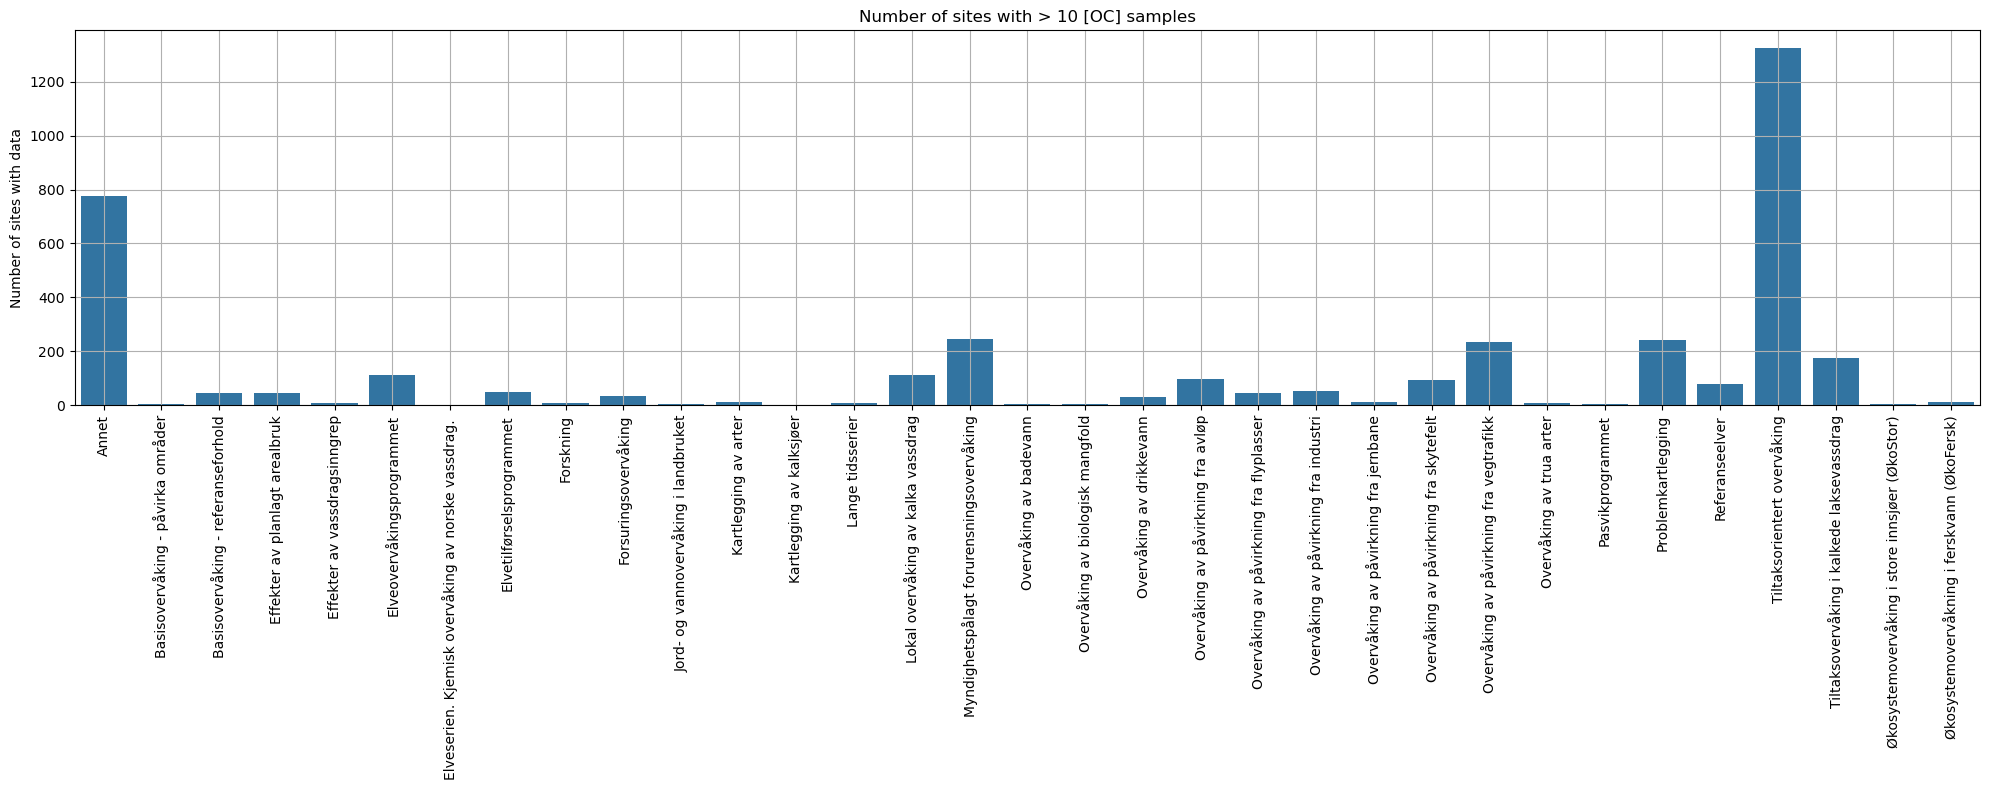

In [63]:
sites_gte_n_samples = pts_df.loc[pts_df['n_samples'] >= min_samps].index
hist_df = chem_df.loc[chem_df[id_col].isin(sites_gte_n_samples)].copy()

groupby_col = "ActivityName"
# groupby_col = "Contractor"
# groupby_col = "Contractor_simple"

sites_by_activity_df = (
    hist_df.groupby(groupby_col)[id_col]
      .nunique()
      .reset_index(name="n_sites")
)

plt.figure(figsize=(20, 8))
sns.barplot(data=sites_by_activity_df, x=groupby_col, y="n_sites")
plt.xticks(rotation=90, ha="center")
plt.ylabel("Number of sites with data")
plt.xlabel("")
plt.title(f"Number of sites with > {min_samps} [OC] samples")
plt.grid()
plt.tight_layout()
plt.show()

In [64]:
sites_by_activity_df['ActivityName'].unique()

array(['Annet', 'Basisovervåking - påvirka områder',
       'Basisovervåking - referanseforhold',
       'Effekter av planlagt arealbruk', 'Effekter av vassdragsinngrep',
       'Elveovervåkingsprogrammet',
       'Elveserien. Kjemisk overvåking av norske vassdrag. ',
       'Elvetilførselsprogrammet', 'Forskning', 'Forsuringsovervåking',
       'Jord- og vannovervåking i landbruket', 'Kartlegging av arter',
       'Kartlegging av kalksjøer', 'Lange tidsserier',
       'Lokal overvåking av kalka vassdrag',
       'Myndighetspålagt forurensningsovervåking',
       'Overvåking av badevann', 'Overvåking av biologisk mangfold',
       'Overvåking av drikkevann', 'Overvåking av påvirkning fra avløp',
       'Overvåking av påvirkning fra flyplasser',
       'Overvåking av påvirkning fra industri',
       'Overvåking av påvirkning fra jernbane',
       'Overvåking av påvirkning fra skytefelt',
       'Overvåking av påvirkning fra vegtrafikk',
       'Overvåking av trua arter', 'Pasvikprogramm

In [65]:
drop_risky_activities = [
    "Annet",
    "Basisovervåking - påvirka områder",
    "Effekter av planlagt arealbruk",
    "Effekter av vassdragsinngrep",
    "Myndighetspålagt forurensningsovervåking",
    "Overvåking av påvirkning fra flyplasser",
    "Overvåking av påvirkning fra jernbane",
    "Overvåking av påvirkning fra skytefelt",
    "Overvåking av påvirkning fra vegtrafikk",
    "Pasvikprogrammet",
    "Problemkartlegging",
    "Tiltaksorientert overvåking",
]

# Keep:
# 'Referanseelver',
# 'Basisovervåking - referanseforhold',
# 'Tiltaksovervåking i kalkede laksevassdrag',
# 'Økosystemovervåking i store innsjøer (ØkoStor)',
# 'Økosystemovervåkning i ferskvann (ØkoFersk)'
# 'Overvåking av trua arter',
# 'Overvåking av påvirkning fra avløp',
# 'Overvåking av påvirkning fra industri',
# 'Overvåking av badevann',
# 'Overvåking av biologisk mangfold',
# 'Overvåking av drikkevann',
# 'Jord- og vannovervåking i landbruket',
# 'Kartlegging av arter',
# 'Kartlegging av kalksjøer',
# 'Lange tidsserier',
# 'Lokal overvåking av kalka vassdrag'
# 'Elveovervåkingsprogrammet',
# 'Elveserien. Kjemisk overvåking av norske vassdrag. ',
# 'Elvetilførselsprogrammet',
# 'Forskning',
# 'Forsuringsovervåking',

# Annual data

In [45]:
catchment_set = "monitored-oc-catchs"
out_folder = r"/home/jovyan/shared/common/norsink/vm_catchments_data"
fname_suffix = "annual_emep_nsdep"
out_fpath = os.path.join(out_folder, f"{catchment_set}_{fname_suffix}.csv")

emep_df = pd.read_csv(out_fpath)
emep_df.tail()

,site_code,emep_din_kghayr,emep_nms_kghayr,year
432577,314-89994,3.41,0.97,2026
432578,314-89994,3.39,0.96,2027
432579,314-89994,3.37,0.95,2028
432580,314-89994,3.35,0.94,2029
432581,314-89994,3.33,0.93,2030


# Compile static, chem and annual

In [46]:
# Start master training dataframe
full_df = ychem_df.copy()

# Add all static variables
full_df = full_df.merge(
    static_df,
    left_on='site_code',
    right_index=True,
    how='left'
)

# Remove capitals
rename_cols = {'Date': 'date',
              'Contractor': 'contractor',
              'TOC_mg_l': 'toc_mg_l'}
full_df = full_df.rename(rename_cols, axis=1)

print(f"Rows: {len(full_df):,}")
print(f"Columns: {len(full_df.columns)}")


Rows: 142,577
Columns: 44


In [47]:
full_df['date'] = pd.to_datetime(full_df['date'])

full_df['year'] = full_df['date'].dt.year

# Add annual
full_df = full_df.merge(
    emep_df[['site_code', 'year', 'emep_nms_kghayr']],
    on=['site_code', 'year'],
    how='left'
)

# QC on annual
n_missing = full_df['emep_nms_kghayr'].isna().sum()

print(f"Rows with missing EMEP data: {n_missing:,}")

if n_missing > 0:
    print(
        full_df.loc[
            full_df['emep_nms_kghayr'].isna(),
            ['site_code', 'year']
        ].drop_duplicates().head(20)
    )

Rows with missing EMEP data: 0


# Daily data

## Basics (doy, day length, top-of-atmosphere radiation)

Year already added above.

Daylength and extraterrestrial solar radiation were calculated from latitude and date using the standard FAO-56 astronomical method (Allen et al., 1998), with adaptations for polar day and polar night conditions. Additional cyclical day-of-year features (sine and cosine) were included to represent seasonality. Note: these are from the catchment outflow. Future improvement: take polygon centroid?

To do: check this citation actually contains these equations/methods!:

Allen, R.G., Pereira, L.S., Raes, D. & Smith, M. (1998). Crop Evapotranspiration: Guidelines for Computing Crop Water Requirements. FAO Irrigation and Drainage Paper 56. Food and Agriculture Organization, Rome.

In [48]:
def daylength_hours(lat_deg, dates):
    """
    Daylength (hours), including correct handling of polar day/night.
    """

    dates = pd.to_datetime(dates)
    J = dates.dt.dayofyear.to_numpy()

    lat = np.radians(np.asarray(lat_deg))

    # Solar declination (radians)
    delta = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)

    # Sunset hour angle term
    x = -np.tan(lat) * np.tan(delta)

    # Numerically safe arccos
    ws = np.arccos(np.clip(x, -1.0, 1.0))

    # Override for polar conditions
    ws = np.where(x <= -1.0, np.pi, ws)  # 24 h daylight
    ws = np.where(x >= 1.0, 0.0, ws)     # 24 h darkness

    return 24.0 * ws / np.pi


def toa_radiation(lat_deg, dates):
    """
    Daily extraterrestrial (top-of-atmosphere) radiation.

    Parameters
    ----------
    lat_deg : scalar or array-like
        Latitude (decimal degrees).
    dates : array-like
        Datetime values.

    Returns
    -------
    ndarray
        Daily TOA radiation (MJ m^-2 day^-1)
    """

    Gsc = 0.0820  # MJ m^-2 min^-1

    dates = pd.to_datetime(dates)
    J = dates.dt.dayofyear.to_numpy()

    lat = np.radians(np.asarray(lat_deg))

    # Inverse relative Earth-Sun distance
    dr = 1 + 0.033 * np.cos(2 * np.pi * J / 365)

    # Solar declination (radians)
    delta = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)

    # Sunset hour angle term
    x = -np.tan(lat) * np.tan(delta)

    # Numerically safe arccos
    ws = np.arccos(np.clip(x, -1.0, 1.0))

    # Override for polar conditions
    ws = np.where(x <= -1.0, np.pi, ws)  # 24 h daylight
    ws = np.where(x >= 1.0, 0.0, ws)     # 24 h darkness

    Ra = (
        (24 * 60 / np.pi)
        * Gsc
        * dr
        * (
            ws * np.sin(lat) * np.sin(delta)
            + np.cos(lat) * np.cos(delta) * np.sin(ws)
        )
    )

    return Ra


# Daylength (hours)
full_df["daylength_hours"] = daylength_hours(
    full_df["lat"],
    full_df["date"],
)

# Daily extraterrestrial radiation (MJ m^-2 day^-1)
full_df["toa_radiation"] = toa_radiation(
    full_df["lat"],
    full_df["date"],
)

# Cyclic day-of-year features
angle = 2 * np.pi * full_df["date"].dt.dayofyear / 365.25

full_df["doy_sin"] = np.sin(angle)
full_df["doy_cos"] = np.cos(angle)

full_df.describe().transpose()

,count,mean,min,25%,50%,75%,max,std
date,142577,2013-02-15 00:53:54.765775616,1980-03-04 00:00:00,2006-01-11 00:00:00,2016-12-08 00:00:00,2021-12-15 00:00:00,2025-12-29 00:00:00,NaN
toc_mg_l,142577.0,5.484003,0.04,2.7,4.5,7.1,250.0,4.451488
lon,142577.0,10.100086,4.693305,7.824137,10.026721,10.948922,30.946283,4.341376
lat,142577.0,60.51073,58.035516,59.200404,59.919237,60.646972,70.962425,2.57016
area_km2,142577.0,1709.687912,0.314898,6.618566,64.422503,406.06789,41691.32573,5941.150903
vassomnr,142577.0,37.560406,1.0,6.0,15.0,29.0,313.0,57.362551
slope_deg_mean,142577.0,9.256721,0.414671,6.080874,8.224854,10.996059,30.474782,4.661117
slope_deg_std,142577.0,6.67009,0.291573,4.506785,6.226574,8.339939,19.427495,2.880838
slope_deg_median,142577.0,7.936068,0.323195,5.15888,6.990786,9.502605,33.910412,4.543705
slope_deg_percentile_5,142577.0,0.989852,0.000371,0.363095,0.739019,1.298624,12.818793,0.934869


In [49]:
# Check looks ok up north (N.B. random sample)
full_df.loc[
    full_df["lat"] > 66.5,
    ["date", "lat", "daylength_hours", "toa_radiation"]
].sample(20)

,date,lat,daylength_hours,toa_radiation
136780,2018-04-04,70.173956,13.987966,18.217604
137464,2024-06-17,69.442456,24.000000,42.503672
137943,2017-02-05,70.229681,4.728225,0.952755
141970,2022-06-03,69.328190,24.000000,40.732975
141533,2023-07-10,69.390100,24.000000,40.381664
134611,2023-09-04,68.716875,14.256324,20.034362
136892,2018-12-04,70.359435,0.000000,0.000000
135753,2019-07-28,68.746528,20.173924,34.993309
138227,2020-10-05,70.186535,9.629855,7.207002
140514,2024-07-17,69.623701,24.000000,38.320020


## GTS API (Q, Temp)

In [51]:
# Folder where individual site parquet files are stored
parquet_dir = Path(r"/home/jovyan/shared/common/norsink/vm_catchments_data/gridded_by_site/processed/daily")

# Not many cols to drop, so probably not worth reading in only the cols we want. But would be
# if there were more cols we don't want (e.g. if lots of features not needed if redoing after feature importance)
drop_cols = [
    "gts_q_daily_m3ps",
    "flag_runoff_interp"
]

date_lookup = (
    full_df
    .groupby('site_code')['date']
    .unique()
    .to_dict()
)

dfs = []

# Only process sites actually needed
site_codes = full_df['site_code'].unique()
for site_code in tqdm(site_codes, desc="Reading parquet files"):

    cur_fpath = parquet_dir / f"{site_code}.parquet"

    if not cur_fpath.exists():
        print(f"Missing file: {cur_fpath.name}")
        continue

    df = pd.read_parquet(cur_fpath)

    df['date'] = pd.to_datetime(df['date'])

    # Keep only dates needed for this site
    needed_dates = date_lookup[site_code]
    df = df.loc[df['date'].isin(needed_dates)]

    df = df.drop(columns=drop_cols, errors='ignore')

    # Quick QC
    if df.duplicated('date').any():
        raise ValueError(
            f"{site_code} contains duplicate dates"
        )

    dfs.append(df)

daily_df = pd.concat(dfs, ignore_index=True)

daily_df.describe().transpose()

Reading parquet files:   0%|          | 0/2552 [00:00<?, ?it/s]

,count,mean,min,25%,50%,75%,max,std
date,141185,2013-01-22 03:35:15.479689728,1980-03-04 00:00:00,2005-11-14 00:00:00,2016-10-31 00:00:00,2021-12-06 00:00:00,2025-12-29 00:00:00,NaN
gts_runoff_daily,141185.0,3.97432,0.0,0.5522,1.55,4.2714,102.1176,6.277659
gts_precip_daily,141185.0,4.070128,0.0,0.0,0.2587,4.2154,142.0,8.590143
gts_temp_daily,141185.0,6.038164,-32.7198,1.0015,6.65,11.7962,24.64,7.427686
gts_runoff_daily_log,141185.0,0.539221,-3.912023,-0.558267,0.451076,1.456613,4.626321,1.289426
gts_runoff_daily_rel_q95,141185.0,0.325716,0.0,0.089066,0.184188,0.41906,9.042545,0.389517
gts_runoff_daily_ecdf,141185.0,0.542233,0.00006,0.311153,0.558445,0.783657,1.0,0.278785
gts_runoff_7d_sum,141185.0,27.934177,0.0,4.1,11.2,31.82,601.8,42.396343
gts_runoff_30d_sum,141185.0,119.619436,0.1,21.6989,54.6062,147.6,1906.8,161.895171
gts_runoff_90d_sum,141184.0,354.0812,1.9459,86.733,196.018,439.1074,3740.3,423.123053


# Merge daily into the rest and save

In [52]:
# Merge onto existing training data

assert len(daily_df) == len(
    daily_df.drop_duplicates(['site_code', 'date'])
)

final_df = full_df.merge(
    daily_df,
    left_on=['site_code', 'date'],
    right_on=['site_code', 'date'],
    how='left'
)

# final_df = final_df.drop(columns='date')
final_df

,site_code,date,contractor,ActivityName,toc_mg_l,lon,lat,area_km2,vassomnr,slope_deg_mean,...,gts_runoff_daily_ecdf,gts_runoff_7d_sum,gts_runoff_30d_sum,gts_runoff_90d_sum,gts_precip_7d_sum,gts_precip_30d_sum,gts_precip_90d_sum,gts_temp_7d_mean,gts_temp_30d_mean,gts_temp_90d_mean
0,001-119928,2011-09-15,Eurofins (location unspecified),Tiltaksorientert overvåking,10.610000,11.653745,59.47652,1008.505005,1,5.542838,...,0.968635,30.6543,68.8774,112.5280,57.5795,204.6595,454.8335,11.902286,13.116717,14.446294
1,001-119928,2012-10-09,Eurofins (location unspecified),Tiltaksorientert overvåking,9.960000,11.653745,59.47652,1008.505005,1,5.542838,...,0.762379,8.7834,26.4669,62.0079,30.0655,130.1295,304.2480,6.048000,7.977317,11.737578
2,001-119928,2013-08-27,Eurofins (location unspecified),Tiltaksorientert overvåking,9.390000,11.653745,59.47652,1008.505005,1,5.542838,...,0.135073,2.2584,9.9790,49.7646,0.2175,92.5385,215.6790,13.295429,14.572167,14.761300
3,001-119928,2014-08-19,Eurofins (location unspecified),Tiltaksorientert overvåking,7.460000,11.653745,59.47652,1008.505005,1,5.542838,...,0.824009,8.0287,14.5404,45.9683,70.9985,160.0015,246.9360,12.480214,17.160600,15.755344
4,001-119928,2015-08-28,Eurofins (location unspecified),Tiltaksorientert overvåking,8.400000,11.653745,59.47652,1008.505005,1,5.542838,...,0.583383,3.1422,14.4502,67.2611,44.9370,75.8890,251.2655,14.987500,14.430683,13.597400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
142572,234-15,2023-10-13,JHI,Forskning,4.158641,24.196780,69.33919,29.723586,234,1.796899,...,0.666647,2.8259,17.6405,113.7035,6.1074,53.5629,277.2149,-3.323300,2.028517,8.278147
142573,234-15,2023-10-14,JHI,Forskning,4.159357,24.196780,69.33919,29.723586,234,1.796899,...,0.666647,2.8148,17.4368,112.7887,6.1074,52.4222,259.7556,-3.810600,1.724567,8.050040
142574,234-15,2023-10-15,JHI,Forskning,4.158641,24.196780,69.33919,29.723586,234,1.796899,...,0.666647,2.8037,17.2887,110.7183,12.3778,58.6926,265.7779,-3.965086,1.531357,7.827078
142575,234-15,2023-10-16,JHI,Forskning,4.161506,24.196780,69.33919,29.723586,234,1.796899,...,0.670962,2.7963,17.1961,108.9183,20.9889,66.8407,270.9964,-3.697886,1.396790,7.665308


In [53]:
# Save

# -------- Column names ---------
id_col = 'site_code'  # set as index for static dfs

# ---------- Directories/filepaths ----------
data_dir = r"/home/jovyan/shared/common/norsink/vm_catchments_data"
catchment_set = "monitored-oc-catchs"

out_folder = os.path.join(data_dir, "training_data")
fname = f"training-data_{y_var[:3]}_full_min-samps-{min_samps}.parquet"
final_df.to_parquet(
    os.path.join(out_folder, fname),
    index=False,
    compression="zstd",
)

# -----------------------------
# Save info about all the features too
col_info = pd.DataFrame({
    "column": final_df.columns,
    "dtype": final_df.dtypes.astype(str).values,
    "n_non_null": final_df.notna().sum().values,
})

colinfo_fname = f"column-info_{y_var[:3]}_full_min-samps-{min_samps}.csv"
col_info.to_csv(os.path.join(out_folder, colinfo_fname), index=False)
col_info

,column,dtype,n_non_null
0,site_code,object,142577
1,date,datetime64[ns],142577
2,contractor,object,142322
3,ActivityName,object,142577
4,toc_mg_l,float64,142577
...,...,...,...
60,gts_precip_30d_sum,float64,142577
61,gts_precip_90d_sum,float64,142576
62,gts_temp_7d_mean,float64,142577
63,gts_temp_30d_mean,float64,142577


In [54]:
print("Columns:", len(final_df.columns))
print("Data:")
print(len(final_df['site_code'].unique()), "sites")
print(len(final_df.dropna(subset=['toc_mg_l'])), "TOC obs")

Columns: 65
Data:
2552 sites
142577 TOC obs


In [55]:
# One row of NaNs in the _90d rolling aggregation window values (from one TOC sample in early 1980)
# Leave it in in case don't use those 90d rolling windows
final_df.loc[final_df['gts_precip_90d_sum'].isna(), :]

,site_code,date,contractor,ActivityName,toc_mg_l,lon,lat,area_km2,vassomnr,slope_deg_mean,...,gts_runoff_daily_ecdf,gts_runoff_7d_sum,gts_runoff_30d_sum,gts_runoff_90d_sum,gts_precip_7d_sum,gts_precip_30d_sum,gts_precip_90d_sum,gts_temp_7d_mean,gts_temp_30d_mean,gts_temp_90d_mean
137468,234-28603,1980-03-04,Not provided,Tiltaksorientert overvåking,3.0,27.121355,69.927721,12474.172492,234,3.724971,...,0.037109,0.2285,1.2656,NaN,5.3895,8.0841,NaN,-13.314414,-17.586413,NaN
